### Matplotlib Introduction

Matplotlib is a comprehensive library for creating static, animated, and interactive visualizations in Python. It provides an object-oriented API for embedding plots into applications using general-purpose GUI toolkits like Tkinter, wxPython, Qt, and GTK+.

In [ ]:
import kagglehub
path = kagglehub.dataset_download("gregorut/videogamesales")

Using Colab cache for faster access to the 'videogamesales' dataset.


In [ ]:
import os
import pandas as pd

# List files in the downloaded directory
print(f"Files in {path}:")
for root, dirs, files in os.walk(path):
    for file in files:
        print(os.path.join(root, file))

Files in /kaggle/input/videogamesales:
/kaggle/input/videogamesales/vgsales.csv


It looks like the main data file is `vgsales.csv`. Let's load this into a pandas DataFrame and display the first few rows.

In [ ]:
import os

# Assuming 'vgsales.csv' is the primary data file
data_file = os.path.join(path, 'vgsales.csv')
df = pd.read_csv(data_file)

# Display the first 5 rows of the DataFrame
display(df.head())

,Rank,Name,Platform,Year,Genre,Publisher,NA_Sales,EU_Sales,JP_Sales,Other_Sales,Global_Sales
0,1,Wii Sports,Wii,2006.0,Sports,Nintendo,41.49,29.02,3.77,8.46,82.74
1,2,Super Mario Bros.,NES,1985.0,Platform,Nintendo,29.08,3.58,6.81,0.77,40.24
2,3,Mario Kart Wii,Wii,2008.0,Racing,Nintendo,15.85,12.88,3.79,3.31,35.82
3,4,Wii Sports Resort,Wii,2009.0,Sports,Nintendo,15.75,11.01,3.28,2.96,33.00
4,5,Pokemon Red/Pokemon Blue,GB,1996.0,Role-Playing,Nintendo,11.27,8.89,10.22,1.00,31.37


### Dataset Information and Missing Values

Let's get a quick overview of the dataset's structure using `df.info()` to see column data types and non-null counts, and then check for the total count of missing values per column using `df.isnull().sum()`.

In [ ]:
print("DataFrame Info:")
df.info()

print("\nMissing values per column:")
print(df.isnull().sum())

DataFrame Info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 16598 entries, 0 to 16597
Data columns (total 11 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   Rank          16598 non-null  int64  
 1   Name          16598 non-null  object 
 2   Platform      16598 non-null  object 
 3   Year          16327 non-null  float64
 4   Genre         16598 non-null  object 
 5   Publisher     16540 non-null  object 
 6   NA_Sales      16598 non-null  float64
 7   EU_Sales      16598 non-null  float64
 8   JP_Sales      16598 non-null  float64
 9   Other_Sales   16598 non-null  float64
 10  Global_Sales  16598 non-null  float64
dtypes: float64(6), int64(1), object(4)
memory usage: 1.4+ MB

Missing values per column:
Rank              0
Name              0
Platform          0
Year            271
Genre             0
Publisher        58
NA_Sales          0
EU_Sales          0
JP_Sales          0
Other_Sales       0
Global_Sales      0
dtype:

### Handling Missing Values

Given the missing values in 'Year' and 'Publisher' columns, we will apply the following imputation strategies:
- **Year**: Impute with the median, as it's a numerical column and median is robust to outliers.
- **Publisher**: Impute with the mode (most frequent publisher), as it's a categorical column.

In [ ]:
# Impute 'Year' with its median
median_year = df['Year'].median()
df['Year'] = df['Year'].fillna(median_year)

# Impute 'Publisher' with its mode
mode_publisher = df['Publisher'].mode()[0]
df['Publisher'] = df['Publisher'].fillna(mode_publisher)

# Verify that missing values have been handled
print("Missing values after imputation:")
print(df.isnull().sum())

Missing values after imputation:
Rank            0
Name            0
Platform        0
Year            0
Genre           0
Publisher       0
NA_Sales        0
EU_Sales        0
JP_Sales        0
Other_Sales     0
Global_Sales    0
dtype: int64


### Total Global Sales Per Genre

To understand which genres have generated the most sales globally, we will aggregate the `Global_Sales` by `Genre` and visualize the totals using a bar chart.

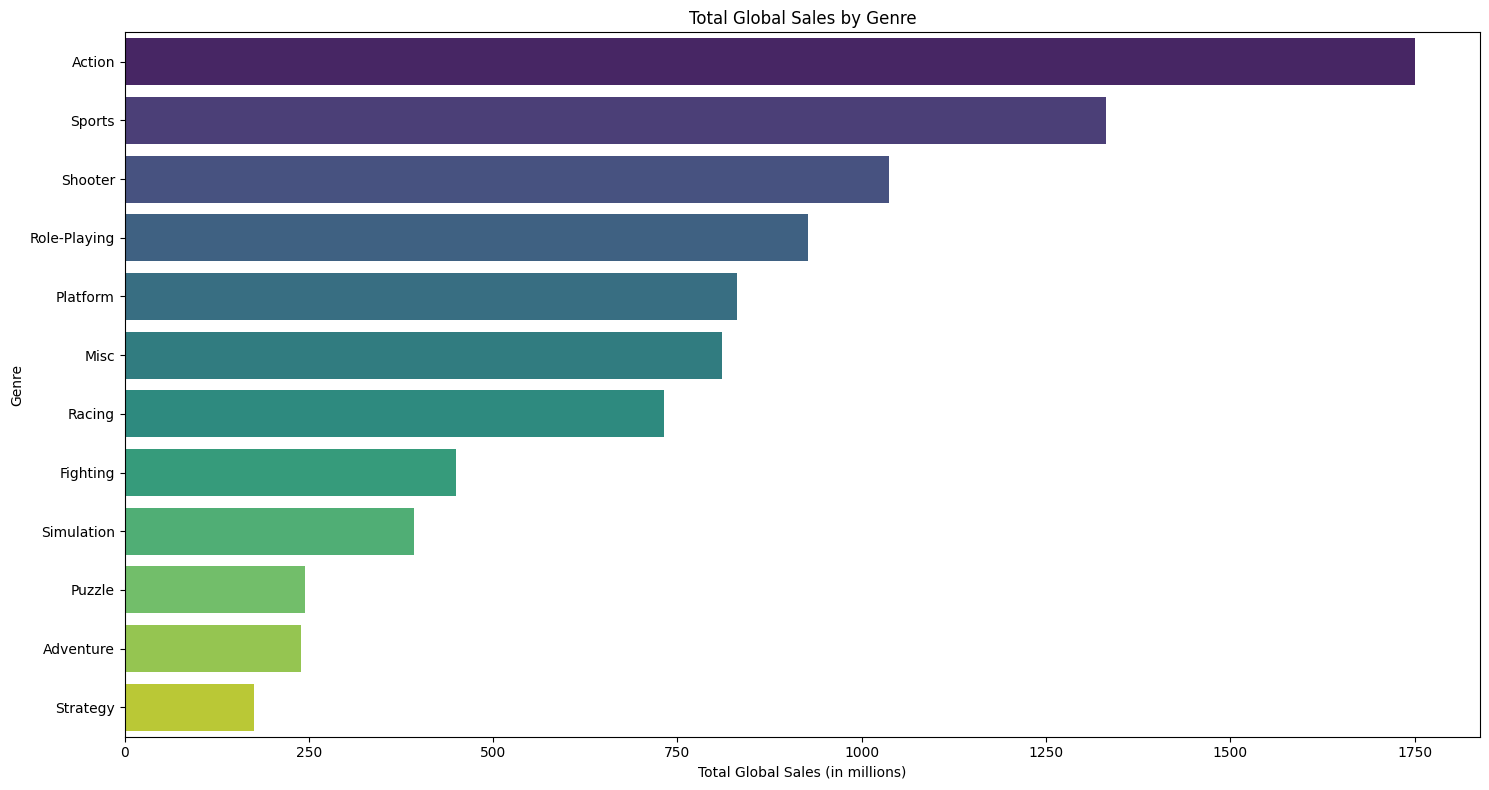

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Calculate total global sales per genre
genre_sales = df.groupby('Genre')['Global_Sales'].sum().reset_index()

# Sort genres by total global sales in descending order
genre_sales = genre_sales.sort_values(by='Global_Sales', ascending=False)

plt.figure(figsize=(15, 8))
sns.barplot(x='Global_Sales', y='Genre', data=genre_sales, palette='viridis', hue='Genre', legend=False)
plt.title('Total Global Sales by Genre')
plt.xlabel('Total Global Sales (in millions)')
plt.ylabel('Genre')
plt.tight_layout()
plt.show()

### Distribution of Global Sales

Let's visualize the distribution of `Global_Sales` to understand its spread, central tendency, and identify any potential outliers or skewness. A histogram is ideal for this purpose.

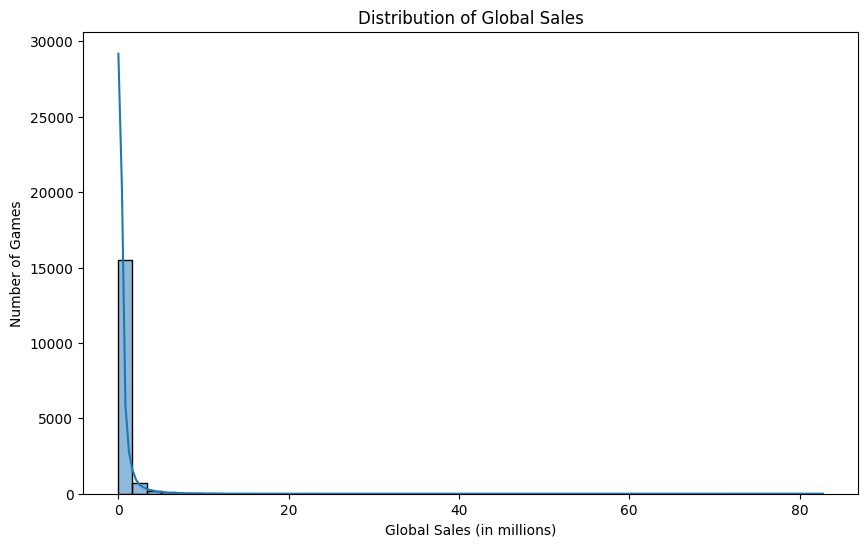

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))
sns.histplot(df['Global_Sales'], bins=50, kde=True)
plt.title('Distribution of Global Sales')
plt.xlabel('Global Sales (in millions)')
plt.ylabel('Number of Games')
plt.show()

### Top 10 Best-Selling Games

To identify and visualize the top 10 best-selling games, we will sort the DataFrame by `Global_Sales` in descending order and then plot the top 10 games using a bar chart.

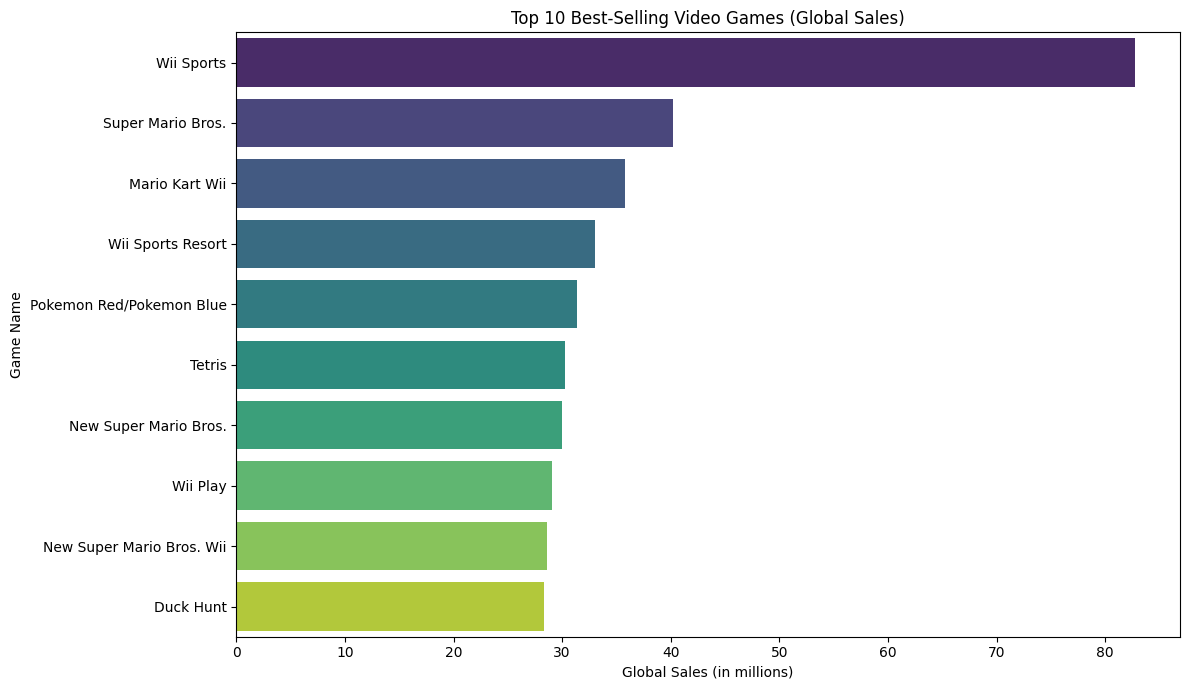

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

# Get the top 10 best-selling games
top_10_games = df.sort_values(by='Global_Sales', ascending=False).head(10)

plt.figure(figsize=(12, 7))
sns.barplot(x='Global_Sales', y='Name', data=top_10_games, palette='viridis', hue='Name', legend=False)
plt.title('Top 10 Best-Selling Video Games (Global Sales)')
plt.xlabel('Global Sales (in millions)')
plt.ylabel('Game Name')
plt.tight_layout()
plt.show()

### Global Sales Distribution by Genre

To compare `Global_Sales` across different `Genre` categories, a boxplot is an excellent choice. It will display the distribution of sales for each genre, showing the median, quartiles, and potential outliers.

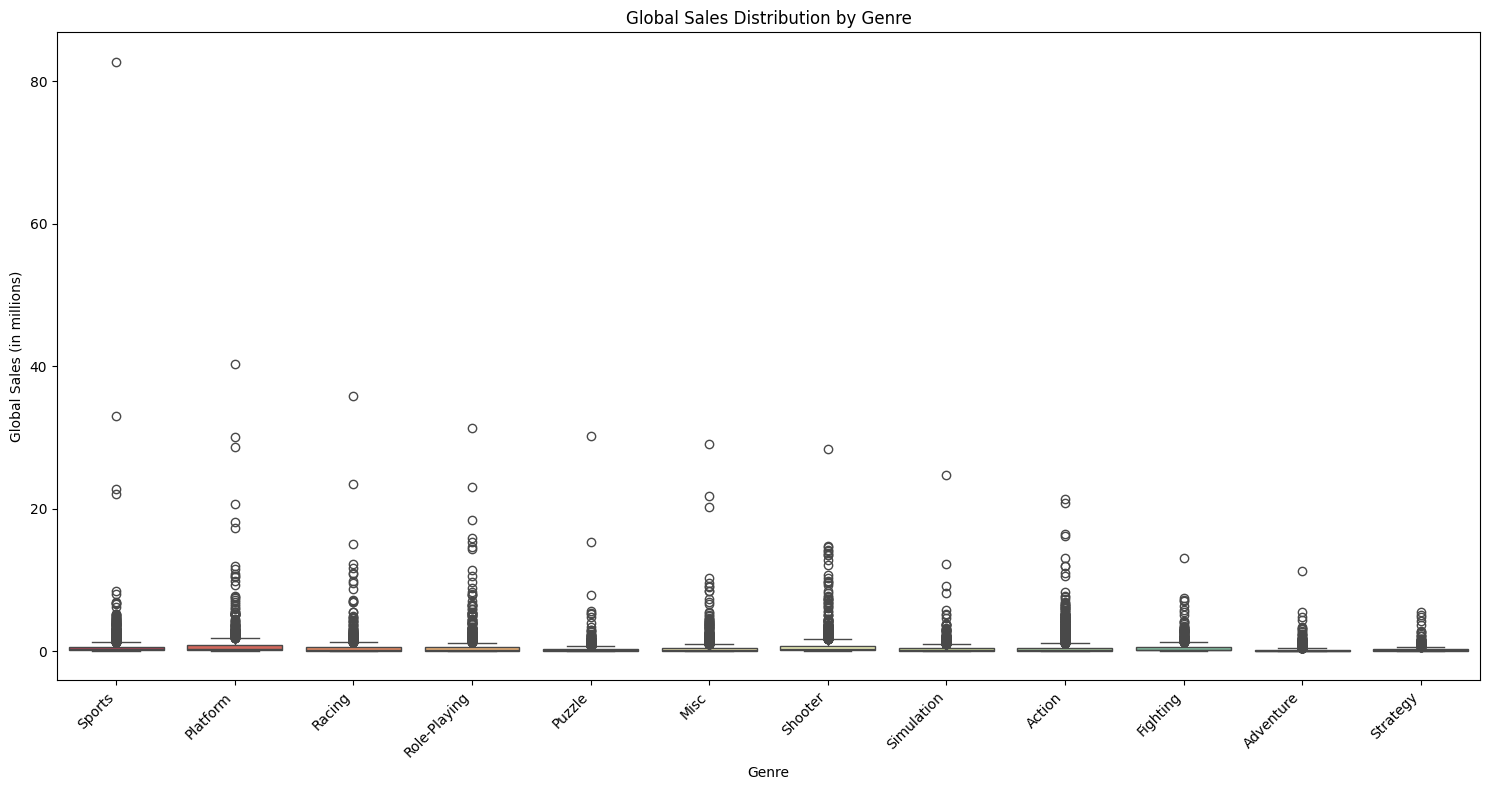

In [ ]:
plt.figure(figsize=(15, 8))
sns.boxplot(x='Genre', y='Global_Sales', data=df, palette='Spectral', hue='Genre', legend=False)
plt.title('Global Sales Distribution by Genre')
plt.xlabel('Genre')
plt.ylabel('Global Sales (in millions)')
plt.xticks(rotation=45, ha='right') # Rotate x-axis labels for better readability
plt.tight_layout()
plt.show()

### Global Sales Trends Over Time

To observe sales trends over time, a scatter plot of `Year` versus `Global_Sales` is appropriate. This can reveal if sales have increased, decreased, or remained relatively stable across different years, and highlight any peak sales periods.

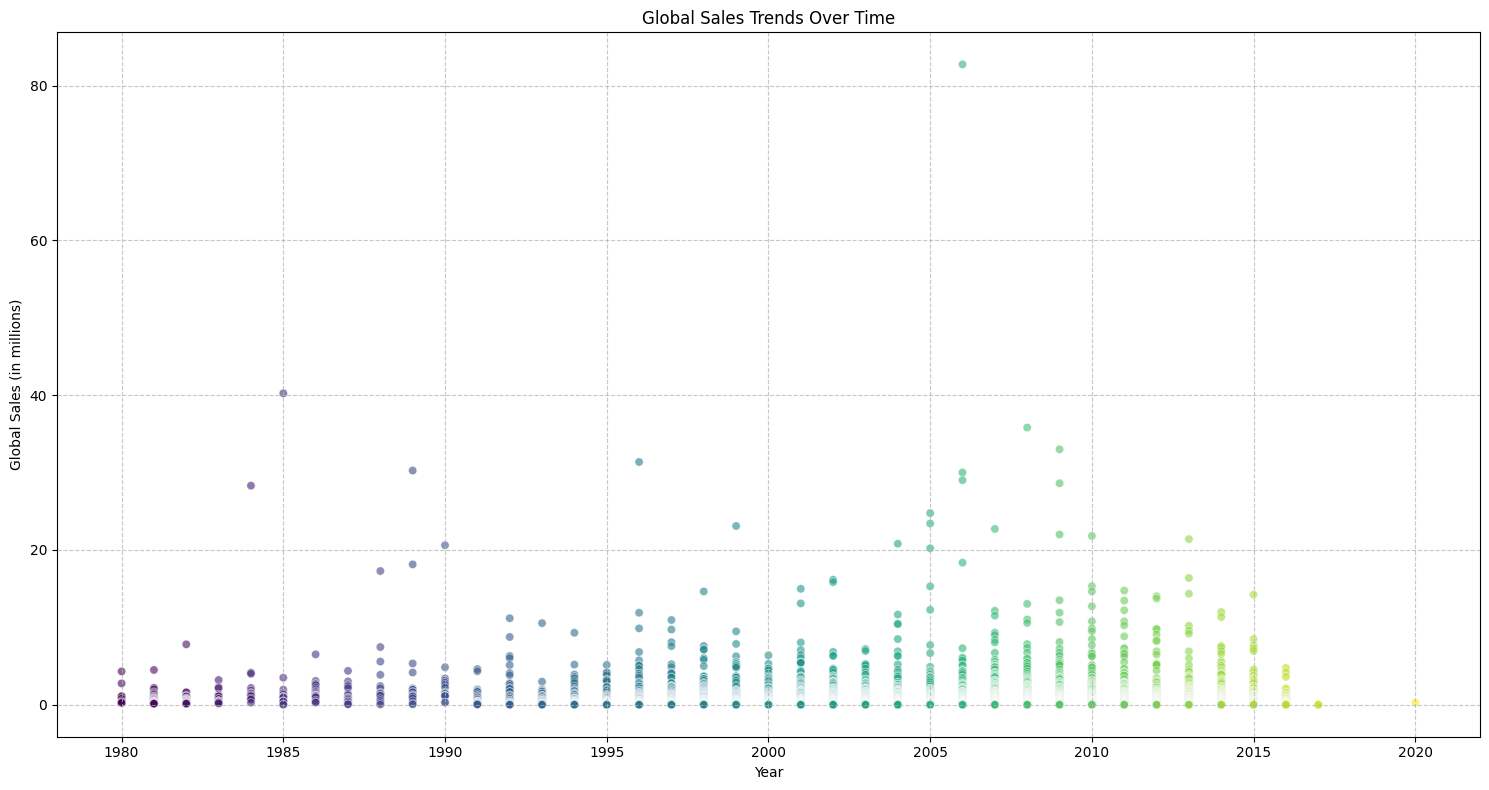

In [ ]:
plt.figure(figsize=(15, 8))
sns.scatterplot(x='Year', y='Global_Sales', data=df, alpha=0.6, hue='Year', palette='viridis', legend=False)
plt.title('Global Sales Trends Over Time')
plt.xlabel('Year')
plt.ylabel('Global Sales (in millions)')
plt.grid(True, linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

### Total Annual Global Sales Trend

To understand how global sales have evolved over time, we will group the data by `Year` and sum the `Global_Sales` for each year. This will allow us to plot the annual sales trend.

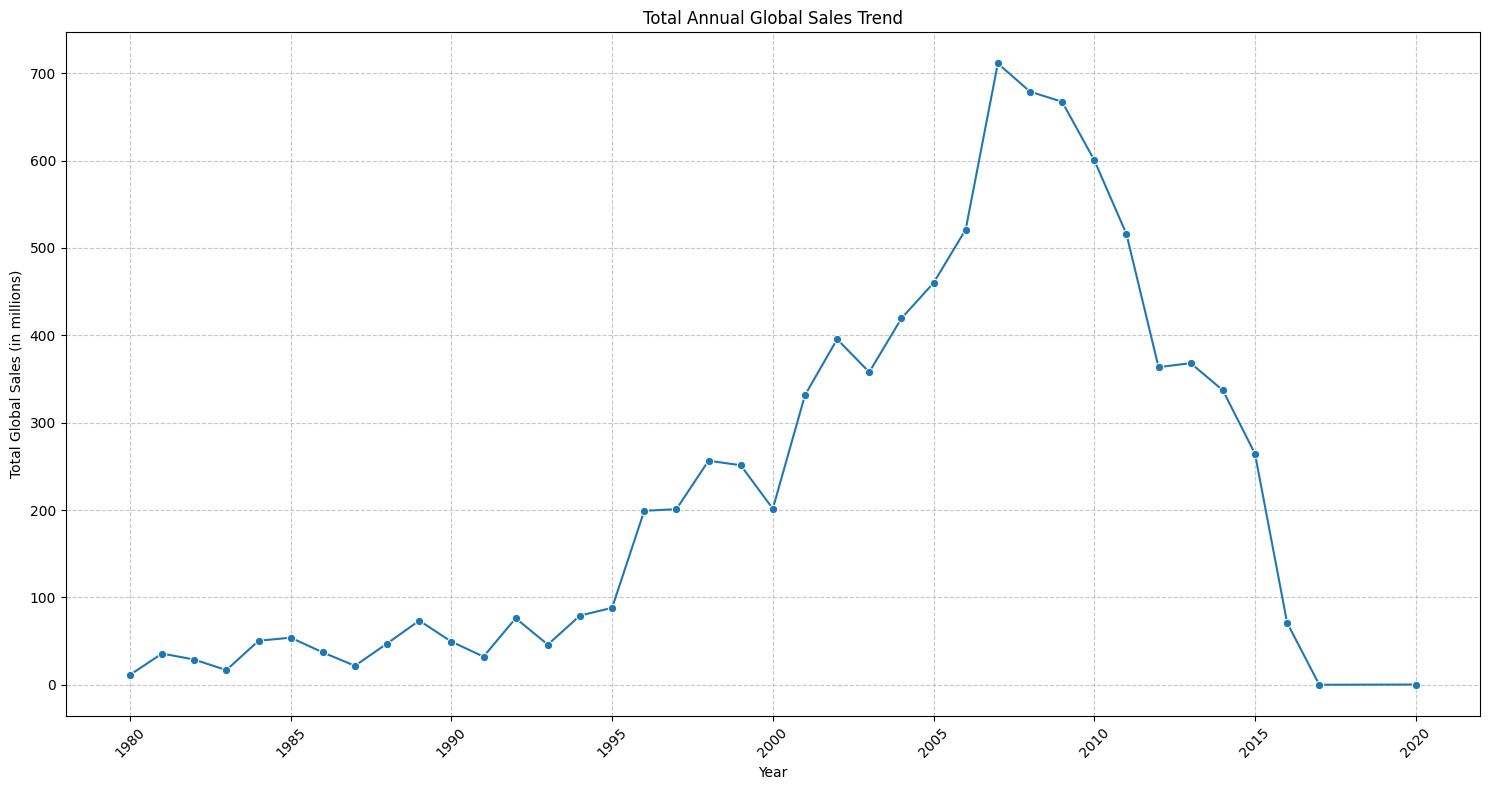

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Group by Year and sum Global_Sales
annual_sales = df.groupby('Year')['Global_Sales'].sum().reset_index()

plt.figure(figsize=(15, 8))
sns.lineplot(x='Year', y='Global_Sales', data=annual_sales, marker='o')
plt.title('Total Annual Global Sales Trend')
plt.xlabel('Year')
plt.ylabel('Total Global Sales (in millions)')
plt.grid(True, linestyle='--', alpha=0.7)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

### Proportion of Global Sales by Top 5 Genres

To highlight the contribution of the highest-selling genres to overall global sales, a pie chart will be used. This will visually represent the proportion of `Global_Sales` accounted for by the top 5 genres.

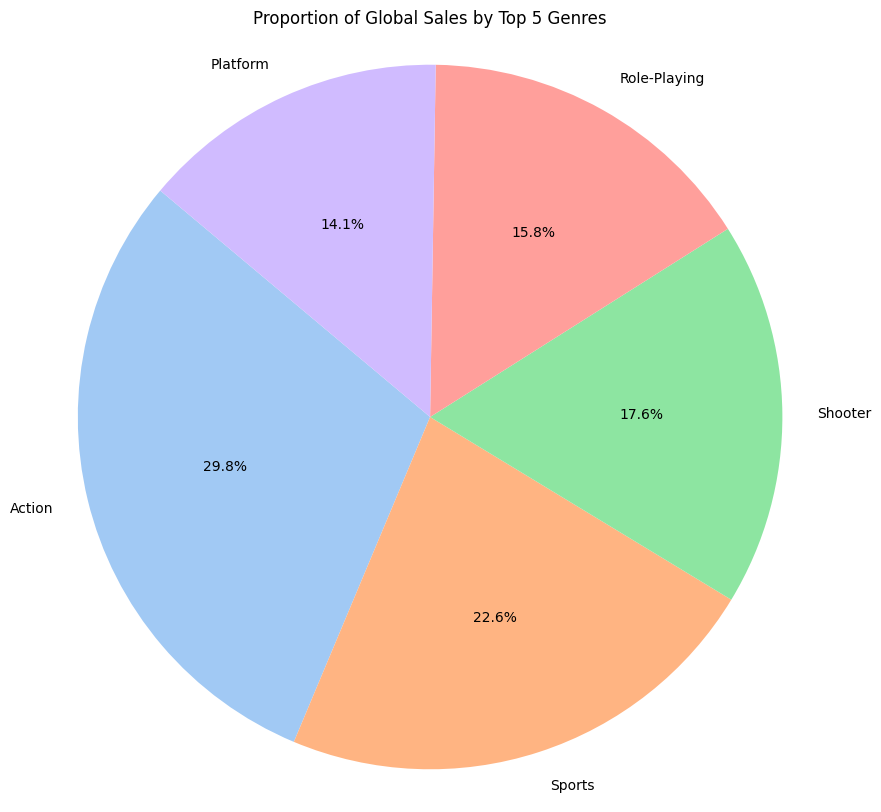

In [ ]:
import matplotlib.pyplot as plt

# Get the top 5 genres by global sales
top_5_genres = genre_sales.head(5)

plt.figure(figsize=(10, 10))
plt.pie(top_5_genres['Global_Sales'], labels=top_5_genres['Genre'], autopct='%1.1f%%', startangle=140, colors=sns.color_palette('pastel'))
plt.title('Proportion of Global Sales by Top 5 Genres')
plt.axis('equal') # Equal aspect ratio ensures that pie is drawn as a circle.
plt.show()